# 01: EDA Dataset Hoaks Indonesia

Tujuan notebook ini:
1. **Menggabungkan** 4 file sumber jadi 1 tabel: `sumber`, `judul`, `teks`, `label`
2. **Kenalan** sama data: jumlah, distribusi label, panjang teks, duplikat, kata yang sering muncul
3. **Mencari "jejak sumber"**, yaitu pola yang bikin model bisa nyontek (bahan untuk M3 & M7)

| Sumber | Label | Kolom teks yang dipakai |
|---|---|---|
| CNN Indonesia, Kompas, Tempo | valid (0) | `FullText` |
| Turnbackhoax | hoaks (1) | `Narasi` (bukan `FullText`! lihat bagian 2) |

Kita pakai folder `Cleaned/` karena cuma di situ ada kolom `Narasi`. Tapi kolom `text_new` / `Clean Narasi` buatan
pembuat dataset **tidak** dipakai. Pembersihan teks kita kerjakan sendiri di M3 biar paham apa yang terjadi.

In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

# Biar teks panjang nggak kepotong terlalu pendek waktu ditampilkan
pd.set_option("display.max_colwidth", 200)

# Cari folder root project. Kalau notebook dijalankan dari folder notebooks/, naik satu level.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw" / "hoax_id" / "Cleaned"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"

RANDOM_STATE = 42  # seed wajib (lihat CLAUDE.md), dipakai tiap kali ambil sampel acak

## 1. Load data mentah

In [3]:
# Nama file per sumber. Key-nya nanti jadi isi kolom "sumber".
FILES = {
    "cnn": "dataset_cnn_10k_cleaned.xlsx",
    "kompas": "dataset_kompas_4k_cleaned.xlsx",
    "tempo": "dataset_tempo_6k_cleaned.xlsx",
    "turnbackhoax": "dataset_turnbackhoax_10_cleaned.xlsx",
}

# Baca semua file Excel ke dict {nama_sumber: DataFrame}.
# Agak lama (~1 menit), karena Excel jauh lebih berat dibaca daripada CSV.
raw = {nama: pd.read_excel(RAW_DIR / file) for nama, file in FILES.items()}

for nama, d in raw.items():
    print(f"{nama:13s} {d.shape}  kolom: {list(d.columns)}")

cnn           (9630, 9)  kolom: ['Unnamed: 0', 'Title', 'Timestamp', 'FullText', 'Tags', 'Author', 'Url', 'text_new', 'hoax']
kompas        (4750, 9)  kolom: ['Unnamed: 0', 'Title', 'Timestamp', 'FullText', 'Tags', 'Author', 'Url', 'text_new', 'hoax']
tempo         (6592, 9)  kolom: ['Unnamed: 0', 'Title', 'Timestamp', 'FullText', 'Tags', 'Author', 'Url', 'text_new', 'hoax']
turnbackhoax  (10381, 11)  kolom: ['Unnamed: 0', 'Title', 'Timestamp', 'FullText', 'Tags', 'Author', 'Url', 'politik', 'Narasi', 'Clean Narasi', 'hoax']


In [4]:
# Jumlah missing value (NaN) per kolom, per sumber.
# "-" artinya kolom itu memang nggak ada di file tersebut.
# Yang paling penting: FullText (valid) dan Narasi (hoaks).
pd.DataFrame({nama: d.isna().sum() for nama, d in raw.items()}).fillna("-")

,cnn,kompas,tempo,turnbackhoax
Author,0.0,337.0,0.0,0.0
Clean Narasi,-,-,-,3879.0
FullText,0.0,27.0,0.0,0.0
Narasi,-,-,-,0.0
Tags,3.0,158.0,1.0,0.0
Timestamp,0.0,21.0,0.0,0.0
Title,0.0,21.0,0.0,0.0
Unnamed: 0,0.0,0.0,0.0,0.0
Url,0.0,0.0,0.0,0.0
hoax,0.0,0.0,0.0,0.0


## 2. Jebakan #1: `FullText` Turnbackhoax itu artikel cek fakta, bukan hoaksnya

Turnbackhoax adalah situs **pemeriksa fakta**. Halaman mereka berisi: judul berlabel `[SALAH]`, isi hoaks yang beredar
(`Narasi`), lalu penjelasan kenapa itu salah. Coba bandingkan:

In [5]:
tbh = raw["turnbackhoax"]

# Ambil 1 baris, bandingkan isi FullText vs Narasi
contoh = tbh.iloc[0]
print("JUDUL   :", contoh["Title"])
print("\nFULLTEXT:", contoh["FullText"][:400])
print("\nNARASI  :", contoh["Narasi"][:400])

JUDUL   : [SALAH] Anies Baswedan Dekat Dengan Aliran Krsiten Sesat Alpha Omega di Papua

FULLTEXT: Hasil Periksa Fakta Gabriela Nauli Sinaga (Universitas Sumatera Utara)
Faktanya, komunitas Alpha Omega yang menyambut Anies Baswedan di Papua bukan Alpha Omega yang merupakan aliran Kristen sesat. Diketahui ternyata banyak nama komunitas Alpha Omega tersebar di Papua dan tidak semuanya merupakan komunitas atau aliran sesat.
Selengkapnya ada di penjelasan.
=====
[KATEGORI]: MISLEADING CONTENT/Konte

NARASI  : 
“BISA DILIHAT SI ONTA YAMAN NGGAK PEDULI ITU APA YANG PENTING DAPAT SUARA SEGALA CARA DEMI KEKUASAAN”
=====
 


`FullText` dibuka dengan *"Hasil Periksa Fakta … Faktanya, …"*. Itu kalimat **bantahan**. Kalau ini yang dipakai,
model cukup belajar "ada kata *Faktanya* → hoaks" dan akurasinya bakal tinggi palsu.
Yang mewakili isi hoaks adalah **`Narasi`**. Judul juga **tidak** dipakai sebagai fitur, karena ada tag `[SALAH]`-nya.

## 3. Jebakan #2: nggak semua artikel Turnbackhoax itu hoaks

In [6]:
# Ambil teks di dalam [..] atau (..) di awal judul. Contoh: "[SALAH] Anies ..." -> "SALAH"
#   ^\s*      = boleh ada spasi di awal
#   [\[(]     = kurung buka: "[" atau "("
#   ([^\])]+) = tangkap semua karakter sampai ketemu kurung tutup
prefix = (
    tbh["Title"].fillna("")
    .str.extract(r"^\s*[\[(]([^\])]+)[\])]", expand=False)
    .str.upper()
    .str.strip()
)
prefix.value_counts(dropna=False).head(25)

Title
SALAH                  8054
HOAX                    570
BENAR                   433
KLARIFIKASI             357
DISINFORMASI            251
BERITA                  179
FALSE                   129
NaN                     116
EDUKASI                  77
TOP 5                    34
FITNAH                   29
MISINFORMASI             19
ISU                      16
ACARA                    15
HOAKS                    13
HASUT                    10
DISINFORMASI+HASUT        6
HOAX+HASUT                6
CLARIFICATION             5
INFORMASI                 4
BERITA, EDUKASI           4
DISINFORMASI+FITNAH       4
HOAX/FITNAH               3
HOAX + HASUT              3
ADMIN POST                3
Name: count, dtype: int64

Ada `[BENAR]`, `[KLARIFIKASI]`, `[BERITA]`, `[EDUKASI]`, `[TOP 5]`, dll. Itu **bukan hoaks**, tapi di file aslinya
semuanya diberi `hoax = 1`. Ini namanya **label noise** (label salah). Kita hanya ambil artikel yang judulnya
diawali kata yang berarti hoaks.

In [7]:
# Kata di awal judul yang artinya "ini hoaks".
#   ^\W*  = boleh diawali simbol apa pun, jadi "[SALAH]", "(HOAX):", "HOAX:", "[SALAH)" semua kena
#   (?:…) = grup tanpa "menangkap" (kalau pakai (…) biasa, pandas kasih warning)
POLA_JUDUL_HOAKS = r"^\W*(?:SALAH|HOAX|HOAKS|DISINFORMASI|MISINFORMASI|FITNAH|HASUT|FALSE)"

is_hoaks = tbh["Title"].fillna("").str.upper().str.contains(POLA_JUDUL_HOAKS, regex=True)
print(f"Judul berlabel hoaks : {is_hoaks.sum()}")
print(f"Dibuang (bukan hoaks): {(~is_hoaks).sum()}")

# Cek sampel judul yang DIBUANG, pastikan memang bukan hoaks
tbh.loc[~is_hoaks, "Title"].sample(10, random_state=RANDOM_STATE)

Judul berlabel hoaks : 9223
Dibuang (bukan hoaks): 1158


9346                                                             [KLARIFIKASI] “Festival Durian 2017 di Klaten, Jawa Tengah”
7249                                                   [BERITA] Penjelasan Pengelola KBS Soal Video Petugas Aniaya Orangutan
6609    [KLARIFIKASI] Polda D.I. Yogyakarta tidak pernah bekerja sama dengan leasing dalam hal pelelangan mobil kredit macet
7394                  [BENAR] Klarifikasi dari Rektor UIN Suska Riau terkait Surat Pemecatan Ustaz Abdul Somad sebagai Dosen
8893                                               [BENAR] Klarifikasi Mahfud Md Terkait Tuduhan Ratna Sarumpaet Terhadapnya
6913                                                                                    [KLARIFIKASI] “polisi juga dianiaya”
9192              [KLARIFIKASI] “Foto Struk Pembelian Bahan Bakar Minyak (Pertalite) Dengan Harga 10 Kali Lipat Lebih Mahal”
8348                                                            [BENAR] “KPAI Bantah 55 Anak Meninggal karena Korban Vaksin”


## 4. Jebakan #3: `Narasi` banyak yang kosong & kecampur penjelasan pemeriksa fakta

In [8]:
narasi = tbh["Narasi"].fillna("").astype(str)

# Banyak Narasi isinya cuma spasi atau "====". Hitung jumlah KATA yang berhuruf (bukan simbol).
n_kata_huruf = narasi.str.findall(r"[A-Za-z]+").str.len()
print("Narasi kosong (< 3 kata)           :", (n_kata_huruf < 3).sum())

# Sebagian Narasi ikut membawa "Penjelasan: ..." dari pemeriksa fakta = bocoran jawaban!
print("Narasi yang mengandung 'Penjelasan':", narasi.str.contains("Penjelasan", case=False).sum())

Narasi kosong (< 3 kata)           : 3909
Narasi yang mengandung 'Penjelasan': 2138


In [9]:
# Format Narasi biasanya:   <isi hoaks>  ====  Penjelasan: <bantahan>
# Jadi kita potong di pembatas PERTAMA yang ketemu dan ambil bagian depannya saja.
#   (?i)         = abaikan huruf besar/kecil
#   (?:=\s*){3,} = tiga "=" atau lebih, boleh berspasi ("====" maupun "= = =")
#   penjelasan\s*: = kata "Penjelasan:" (untuk kasus yang nggak ada pembatas "=")
POLA_PEMBATAS = r"(?i)(?:=\s*){3,}|penjelasan\s*:"

def ambil_isi_hoaks(teks: str) -> str:
    """Ambil bagian sebelum pembatas pertama, lalu buang spasi di ujung."""
    return re.split(POLA_PEMBATAS, teks, maxsplit=1)[0].strip()

narasi_bersih = narasi.apply(ambil_isi_hoaks)
print("Setelah dipotong, masih ada 'Penjelasan':", narasi_bersih.str.contains("Penjelasan", case=False).sum())

Setelah dipotong, masih ada 'Penjelasan': 181


In [10]:
# Lihat contoh sebelum vs sesudah dipotong
i = narasi[narasi.str.contains("Penjelasan", case=False)].index[0]
print("SEBELUM:\n", narasi[i][:600])
print("\nSESUDAH:\n", narasi_bersih[i][:600])

SEBELUM:
 
“M£g∆w∆ti Di Panggil B4waslu:exclamation:️Bvntut Uc4pan Ketumny4 P-di Bak4l Di Blackl1st Dari P1lpres.”
“Buntut Hinaannya!! Mak Mega Di Panggil Bawaslu PD1 Bakal Di Blacklist Dari Peserta Pilpres Tak Bisa Usung Capres”
= = =
Penjelasan:
Beredar sebuah unggahan di Facebook dengan narasi yang menyebut bahwa Ketua Umum PDI Perjuangan, Megawati Soekarnoputri, dipanggil Bawaslu. Dalam narasi pada thumbnail video yang disematkan, menyebut bahwa panggilan tersebut buntut dari ucapannya yang mengakibatkan Bawaslu mem-blacklist PDI Perjuangan dari peserta Pilpres sehingga tidak bisa mengusung Capres. 

SESUDAH:
 “M£g∆w∆ti Di Panggil B4waslu:exclamation:️Bvntut Uc4pan Ketumny4 P-di Bak4l Di Blackl1st Dari P1lpres.”
“Buntut Hinaannya!! Mak Mega Di Panggil Bawaslu PD1 Bakal Di Blacklist Dari Peserta Pilpres Tak Bisa Usung Capres”


## 5. Gabungkan jadi satu tabel

In [11]:
# --- Hoaks (label 1): cuma artikel yang judulnya hoaks, teksnya pakai narasi yang sudah dipotong ---
hoaks = pd.DataFrame({
    "sumber": "turnbackhoax",
    "judul": tbh["Title"],   # disimpan buat referensi saja, BUKAN fitur model
    "teks": narasi_bersih,
    "label": 1,
})[is_hoaks]

# --- Valid (label 0): CNN, Kompas, Tempo, teksnya pakai FullText ---
valid = pd.concat(
    [
        pd.DataFrame({"sumber": nama, "judul": raw[nama]["Title"], "teks": raw[nama]["FullText"], "label": 0})
        for nama in ["cnn", "kompas", "tempo"]
    ],
    ignore_index=True,
)

# Tumpuk jadi satu tabel. ignore_index=True = nomor baris diulang dari 0.
df = pd.concat([hoaks, valid], ignore_index=True)
df["teks"] = df["teks"].fillna("").astype(str)

# Buang teks yang kosong/terlalu pendek (< 3 kata berhuruf), berlaku untuk semua sumber
cukup_panjang = df["teks"].str.findall(r"[A-Za-z]+").str.len() >= 3
print("Dibuang karena kosong/terlalu pendek:", (~cukup_panjang).sum())
df = df[cukup_panjang].reset_index(drop=True)

print("Ukuran akhir:", df.shape)
df.sample(5, random_state=RANDOM_STATE)

Dibuang karena kosong/terlalu pendek: 3129
Ukuran akhir: (27066, 4)


,sumber,judul,teks,label
14991,cnn,Ketum PAN Zulhas Ikut ke Istana Jumpa Jokowi & Parpol Koalisi,"Jakarta, CNN Indonesia -- Ketua Umum Partai Amanat Nasional (Ketum PAN), Zulkifli Hasan (Zulhas), ikut dalam pertemuan antara Presiden Joko Widodo (Jokowi) dengan jajaran pemimpin dari partai poli...",0
6879,cnn,Rieke Ingatkan Pesan Pilpres 2024 Megawati: Jangan Ambil Kader Gue,"Jakarta, CNN Indonesia -- Anggota DPR RI PDI Perjuangan (PDIP) Rieke Diah Pitaloka menegaskan titah Ketua Umum PDIP Megawati Soekarnoputri agar tak ada pihak lain yang mengusung kader mereka menja...",0
22875,tempo,"Presiden Jokowi Panggil Hadi Tjahjanto, Pengamat: Prabowo Subianto Tetap Aman","TEMPO.CO, Jakarta - Pengamat politik dari Universitas Al Azhar Ujang Komarudin menilai pemanggilan Mantan Panglima TNI (Purn) Marsekal Hadi Tjahjanto oleh Presiden Jokowi di tengah isu reshuffle k...",0
10319,cnn,Kemenag Buka Suara Pemkot Ternate Gelar Salat Iduladha 9 Juli,"Jakarta, CNN Indonesia -- Direktur Jendral (Dirjen) Bina Masyarakat Islam Kementerian Agama (Kemenag) Kamaruddin Amin mengimbau kepada lembaga pemerintah untuk mengikuti keputusan pemerintah terka...",0
26634,tempo,Survei NEW INDONESIA: Elektabilitas NasDem Masih Jeblok,"TEMPO.CO, Jakarta - Elektabilitas Partai NasDem turun menjadi 3,5 persen atau di bawah ambang batas parlemen 4 persen. Data itu terungkap lewat survei NEW INDONESIA Research & Consulting pada Janu...",0


## 6. Distribusi label

In [12]:
# value_counts() = hitung jumlah tiap label; normalize=True = dalam bentuk proporsi (0-1)
distribusi = pd.DataFrame({
    "jumlah": df["label"].value_counts(),
    "persen": (df["label"].value_counts(normalize=True) * 100).round(1),
}).rename(index={0: "valid (0)", 1: "hoaks (1)"})
print(distribusi, "\n")

# Rincian per sumber
print(df.groupby(["label", "sumber"]).size())

           jumlah  persen
label                    
valid (0)   20945    77.4
hoaks (1)    6121    22.6 

label  sumber      
0      cnn             9630
       kompas          4723
       tempo           6592
1      turnbackhoax    6121
dtype: int64


**Pikirkan:** kalau model *selalu* menebak "valid", akurasinya berapa? Itu patokan minimum (Dummy baseline, M4).
Karena datanya nggak seimbang, akurasi saja bisa menyesatkan. Nanti kita butuh precision, recall, dan F1
(StatQuest: *Confusion Matrix* dan *Sensitivity and Specificity*).

## 7. Panjang teks per label

In [13]:
# Jumlah kata per teks: pecah teks di spasi, lalu hitung jumlah potongannya
df["n_kata"] = df["teks"].str.split().str.len()

# Statistik ringkas per label. Perhatikan kolom 50% (= median)
df.groupby("label")["n_kata"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,20945.0,337.2,139.9,43.0,253.0,312.0,390.0,3472.0
1,6121.0,56.4,88.8,1.0,14.0,28.0,61.0,2091.0


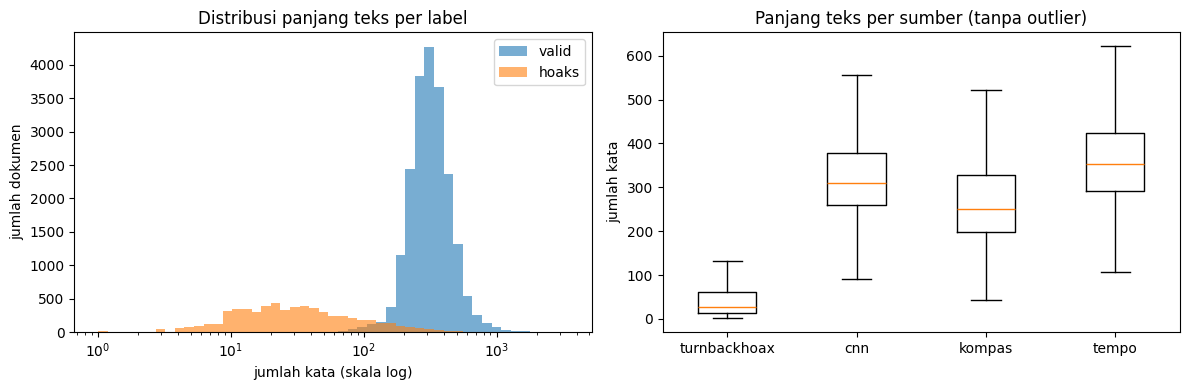

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Kiri: histogram panjang teks. Sumbu x pakai skala log karena ada teks yang ribuan kata.
# logspace = bikin batas bin yang jaraknya rata di skala log
bins = np.logspace(0, np.log10(df["n_kata"].max()), 50)
for label, nama in [(0, "valid"), (1, "hoaks")]:
    axes[0].hist(df.loc[df["label"] == label, "n_kata"], bins=bins, alpha=0.6, label=nama)
axes[0].set_xscale("log")
axes[0].set_xlabel("jumlah kata (skala log)")
axes[0].set_ylabel("jumlah dokumen")
axes[0].set_title("Distribusi panjang teks per label")
axes[0].legend()

# Kanan: boxplot per sumber. Garis tengah kotak = median. showfliers=False = outlier disembunyikan
urutan = ["turnbackhoax", "cnn", "kompas", "tempo"]
axes[1].boxplot([df.loc[df["sumber"] == s, "n_kata"] for s in urutan], tick_labels=urutan, showfliers=False)
axes[1].set_ylabel("jumlah kata")
axes[1].set_title("Panjang teks per sumber (tanpa outlier)")

plt.tight_layout()
plt.savefig(FIG_DIR / "eda_panjang_teks.png", dpi=120)  # disimpan buat README nanti
plt.show()

Teks hoaks (unggahan medsos/WhatsApp) **jauh lebih pendek** daripada artikel berita. Artinya model bisa menebak
dengan cukup baik *cuma dari panjang teks*. Itu soal **gaya/format**, bukan isi. Catat sebagai calon jejak sumber.

## 8. Duplikat

Di sini kita cuma **menghitung**. Penghapusannya dilakukan di M2 (`src/split.py`), **sebelum** split.

In [15]:
# Normalisasi ringan dulu (huruf kecil + spasi dirapikan), biar duplikat yang beda spasi juga ketahuan
teks_norm = df["teks"].str.lower().str.split().str.join(" ")

# duplicated()           = True untuk salinan ke-2, ke-3, dst. (salinan pertama dianggap asli)
# duplicated(keep=False) = True untuk SEMUA baris yang punya kembaran
print("Baris yang punya kembaran          :", teks_norm.duplicated(keep=False).sum())
print("Baris yang dibuang kalau di-dedupe :", teks_norm.duplicated().sum())
print("\nSalinan yang dibuang per sumber:")
print(df[teks_norm.duplicated()].groupby("sumber").size())

# Paling bahaya: teks yang sama persis tapi labelnya beda
label_per_teks = df.groupby(teks_norm)["label"].nunique()
print("\nTeks identik tapi labelnya berbeda:", (label_per_teks > 1).sum())

Baris yang punya kembaran          : 27
Baris yang dibuang kalau di-dedupe : 14

Salinan yang dibuang per sumber:
sumber
tempo            1
turnbackhoax    13
dtype: int64

Teks identik tapi labelnya berbeda: 0


## 9. Kata paling sering per label

> Catatan: di sini `CountVectorizer` di-fit ke **semua** data karena tujuannya cuma eksplorasi, bukan melatih model.
> Mulai M4, vectorizer **wajib** di-fit di data train saja (pakai `Pipeline`).

In [16]:
# CountVectorizer = ubah teks jadi tabel hitungan kata (bag of words).
# token_pattern: cuma ambil "kata" dari huruf a-z minimal 2 karakter (angka & tanda baca diabaikan)
cv = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
X = cv.fit_transform(df["teks"])      # matriks sparse: baris = dokumen, kolom = kata
kata = cv.get_feature_names_out()     # daftar kata sesuai urutan kolom

def top_kata(mask, n=20):
    """Jumlahkan hitungan tiap kata di dokumen yang dipilih mask, ambil n kata terbanyak."""
    total = np.asarray(X[mask.to_numpy()].sum(axis=0)).ravel()  # total kemunculan per kata
    idx = total.argsort()[::-1][:n]                               # index n terbesar
    return pd.Series(total[idx], index=kata[idx])

top_valid = top_kata(df["label"] == 0)
top_hoaks = top_kata(df["label"] == 1)
pd.DataFrame({
    "valid": top_valid.index, "n_valid": top_valid.values,
    "hoaks": top_hoaks.index, "n_hoaks": top_hoaks.values,
})

,valid,n_valid,hoaks,n_hoaks
0,yang,149116,di,6838
1,dan,123056,dan,6120
2,di,114533,yang,5825
3,itu,75592,ini,3996
4,juga,69886,untuk,2589
5,partai,64869,dari,2561
6,ini,61888,dengan,2265
7,dengan,60363,tidak,2137
8,dalam,57463,yg,2053
9,untuk,56387,ada,1905


Kebanyakan isinya kata umum seperti *yang, dan, di, ini*, yaitu **stopword**. Kata-kata ini nggak banyak membedakan label.
Mau dibuang atau tidak? Jangan diputuskan sekarang. Nanti dicoba dua-duanya di M6.

## 10. ⭐ Mencari "jejak sumber"

Jejak sumber = pola yang muncul (hampir) **hanya di satu label** karena *asal datanya*, bukan karena isinya hoaks/valid.
Model yang belajar dari pola ini akan terlihat pintar di data ini, tapi gagal di dunia nyata.

In [17]:
# 10a. Lihat 60 karakter pertama dari 5 teks acak per sumber.
# Pembuka teks sering jadi "tanda tangan" media. repr() = tampilkan apa adanya, termasuk \n
for s in ["cnn", "kompas", "tempo", "turnbackhoax"]:
    print(f"\n=== {s} ===")
    for t in df.loc[df["sumber"] == s, "teks"].sample(5, random_state=RANDOM_STATE):
        print("  ", repr(t[:60]))


=== cnn ===
   'Jakarta, CNN Indonesia -- Presiden\xa0Partai Buruh Said Iqbal m'
   'Jakarta, CNN Indonesia -- Komisi Pemilihan Umum (KPU) resmi '
   'Jakarta, CNN Indonesia -- Baru-baru ini jagat maya dihebohka'
   'Jakarta, CNN Indonesia -- Menteri Koordinator Bidang Maritim'
   'Jakarta, CNN Indonesia -- Direktur Indonesian Parlemen Cente'

=== kompas ===
   'BANDUNG, KOMPAS.com- Dewan Pimpinan Wilayah (DPW) Partai Keb'
   'JAKARTA, KOMPAS.com - Hasil survei Litbang Kompas pada Oktob'
   'KOMPAS.com -\xa0Beredar narasi di media sosial berupa tangkapan'
   ' KOMPAS.com - Saat mengunjungi Kota Garut, Calon Presiden no'
   ' JAKARTA, KOMPAS.com - Artikel tentang komunikasi politik Ke'

=== tempo ===
   'TEMPO.CO, Jakarta - Wakil Menteri Hukum dan HAM Edward Omar '
   'TEMPO.CO, Jakarta - Di tengah merebaknya kabar reshuffle kab'
   'TEMPO.CO, Jakarta - Rapat Gabungan Majelis Permusyawaratan R'
   'TEMPO.CO, Jakarta - Menteri Koordinator Bidang Kemaritiman d'
   'TEMPO.CO, Jakarta - Me

In [18]:
# 10b. Pola yang dicurigai. Untuk tiap pola: berapa % dokumen di tiap label yang mengandungnya?
POLA_CURIGA = {
    "dateline CNN ('CNN Indonesia --')": r"CNN Indonesia\s*--",
    "dateline Kompas ('KOMPAS.com')": r"KOMPAS\.com",
    "dateline Tempo ('TEMPO.CO')": r"TEMPO\.CO",
    "'Baca juga'": r"[Bb]aca [Jj]uga",
    "zona waktu 'WIB'": r"\bWIB\b",
    "URL (http / www)": r"https?://|www\.",
    "tanda kutip miring “ ”": r"[“”]",
    "KATA KAPITAL SEMUA (>= 5 huruf)": r"\b[A-Z]{5,}\b",
    "tanda seru (!)": r"!",
    "kata 'Faktanya'": r"Faktanya",
}

hasil = pd.DataFrame({
    nama: df.groupby("label")["teks"].apply(lambda s: s.str.contains(pola, regex=True).mean() * 100)
    for nama, pola in POLA_CURIGA.items()
}).T.round(1)
hasil.columns = ["% valid", "% hoaks"]
hasil

,% valid,% hoaks
dateline CNN ('CNN Indonesia --'),46.0,0.0
dateline Kompas ('KOMPAS.com'),20.1,0.0
dateline Tempo ('TEMPO.CO'),31.5,0.0
'Baca juga',31.9,0.0
zona waktu 'WIB',4.7,1.0
URL (http / www),0.7,9.6
tanda kutip miring “ ”,17.1,78.0
KATA KAPITAL SEMUA (>= 5 huruf),98.4,37.8
tanda seru (!),3.8,19.0
kata 'Faktanya',0.2,0.4


In [19]:
# 10c. Cari kata yang muncul hampir HANYA di satu label.
# binary=True -> yang dihitung "ada / tidak ada" di dokumen, bukan berapa kali muncul
# min_df=30   -> abaikan kata yang muncul di < 30 dokumen (terlalu jarang, nggak representatif)
cv_bin = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b", binary=True, min_df=30)
Xb = cv_bin.fit_transform(df["teks"])
kata_b = cv_bin.get_feature_names_out()

is_h = (df["label"] == 1).to_numpy()
p_hoaks = np.asarray(Xb[is_h].mean(axis=0)).ravel()   # proporsi dokumen hoaks yang mengandung kata
p_valid = np.asarray(Xb[~is_h].mean(axis=0)).ravel()  # proporsi dokumen valid yang mengandung kata

# Log rasio: positif = condong ke hoaks, negatif = condong ke valid, 0 = seimbang.
# + 0.001 supaya nggak membagi dengan nol kalau kata sama sekali nggak muncul di salah satu label
log_rasio = np.log((p_hoaks + 1e-3) / (p_valid + 1e-3))

skor = pd.DataFrame({
    "kata": kata_b,
    "% hoaks": (p_hoaks * 100).round(1),
    "% valid": (p_valid * 100).round(1),
    "log_rasio": log_rasio.round(2),
})
print("20 kata paling condong ke HOAKS:")
display(skor.nlargest(20, "log_rasio"))
print("20 kata paling condong ke VALID:")
display(skor.nsmallest(20, "log_rasio"))

20 kata paling condong ke HOAKS:


,kata,% hoaks,% valid,log_rasio
8757,terjemahan,3.7,0.0,3.51
9374,www,3.8,0.1,3.25
2250,dot,2.6,0.0,3.24
6895,permalink,2.3,0.0,3.19
2412,fafhh,2.3,0.0,3.18
2679,groups,2.4,0.0,3.12
327,archive,2.3,0.0,3.11
2915,http,2.7,0.0,3.09
8578,tdk,2.5,0.0,2.95
8884,this,2.3,0.1,2.77


20 kata paling condong ke VALID:


,kata,% hoaks,% valid,log_rasio
61,advertisement,0.0,46.0,-6.13
2553,gambas,0.0,45.2,-6.12
7545,resume,0.0,46.0,-5.98
7773,scroll,0.0,46.0,-5.98
1360,content,0.1,46.0,-5.54
1346,cnn,0.3,46.1,-4.85
2256,dpp,0.1,20.0,-4.71
7173,ppp,0.0,12.1,-4.66
9101,ujarnya,0.1,20.7,-4.57
1708,digelar,0.0,14.0,-4.55


## 11. Ringkasan temuan

**Jumlah data & distribusi label**
- Setelah dibersihkan: **27.066 baris**. Valid **20.945 (77,4%)** = CNN 9.630 + Kompas 4.723 + Tempo 6.592. Hoaks **6.121 (22,6%)** dari Turnbackhoax.
- Yang dibuang: 1.158 artikel Turnbackhoax yang bukan hoaks ([BENAR], [KLARIFIKASI], [BERITA], dll.) dan 3.129 teks kosong/terlalu pendek.
- Datanya **tidak seimbang**. Model yang selalu menebak "valid" sudah dapat akurasi 77,4%. Itu patokan minimum (Dummy baseline M4), dan alasan kenapa nanti harus lihat precision/recall/F1, bukan cuma akurasi.

**Panjang teks**
- Median hoaks **28 kata** vs valid **312 kata**. Teks valid paling pendek pun 43 kata, sedangkan 75% hoaks di bawah 61 kata.
- Penyebabnya format: hoaks = unggahan medsos/WhatsApp, valid = artikel berita utuh. Panjang teks saja hampir cukup untuk menebak label.

**Duplikat**
- 27 baris punya kembaran. Kalau di-dedupe, **14 dibuang** (13 Turnbackhoax, 1 Tempo). Hoaks yang sama dicek ulang di beberapa artikel.
- **Tidak ada** teks identik dengan label berbeda. Aman.

**Daftar jejak sumber**

| Jejak | % valid | % hoaks | Kenapa curang |
|---|---|---|---|
| Dateline "CNN Indonesia --" / "KOMPAS.com" / "TEMPO.CO" | 46 / 20 / 32 | 0 | Nama media, bukan isi berita |
| "Baca juga" | 31,9 | 0 | Format halaman portal berita |
| "advertisement", "scroll to resume content", "gambas" | ~46 | 0 | Sampah scraping halaman CNN |
| Tanda kutip miring “ ” | 17,1 | 78,0 | Pemeriksa fakta selalu mengutip klaim yang dibantah |
| URL & token link (www, http, dot, permalink, archive, groups) | ~0 | 2–10 | Link arsip yang ditambahkan pemeriksa fakta |
| "terjemahan" | 0 | 3,7 | Catatan terjemahan dari pemeriksa fakta, bukan bagian hoaks |
| Panjang teks | — | — | Lihat atas |
| Sisa "Penjelasan" | — | 181 teks | Pemotongan belum sempurna, cek lagi di M3 |

**Kata dari 10c: isi vs jejak sumber**
- *Masuk akal secara isi/gaya hoaks:* singkatan informal (yg, tdk, dgn, utk, tgl), "share", "assalamualaikum", tanda seru. Ini memang ciri pesan berantai. Tapi hati-hati: ini membedakan **gaya medsos vs gaya berita**, bukan benar vs salah.
- *Gaya jurnalistik:* ujarnya, menurutnya, menilai, menyebut, pihaknya. Ini ciri **genre** berita, bukan bukti kebenaran.
- *Bias topik/waktu:* partai, golkar, ppp, pkb, dpp, jokowi, mentarang, plta. Berita valid di dataset ini didominasi **politik 2022–2023**, jadi model bisa belajar "topik politik → valid".
- *Murni jejak sumber:* advertisement, gambas, scroll, resume, content, cnn, www, permalink, archive, terjemahan.

**Kalau model dapat akurasi 99%, apakah itu bukti model paham hoaks?**
**Tidak.** Di dataset ini, label hampir sama dengan "artikel portal berita vs unggahan medsos". Model bisa 99% benar cuma dari dateline, panjang teks, tanda kutip, atau singkatan informal. Di dunia nyata, hoaks yang ditulis rapi ala berita akan lolos, dan unggahan medsos yang isinya benar akan dituduh hoaks. Model ini mendeteksi **gaya**, bukan **kebenaran fakta**. Ini yang dibuktikan di M7.

## 12. Simpan tabel gabungan

Disimpan ke `data/processed/` (tidak di-commit) untuk dipakai `src/split.py` di M2.
**Belum** di-dedupe. Itu tugas `split.py`.

In [20]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out_path = PROCESSED_DIR / "dataset_gabungan.csv"

# Kolom n_kata nggak ikut disimpan karena bisa dihitung ulang kapan saja
simpan = df[["sumber", "judul", "teks", "label"]]
simpan.to_csv(out_path, index=False)
print("Tersimpan:", out_path, simpan.shape)

Tersimpan: d:\Dhanes\Fake News Detection\data\processed\dataset_gabungan.csv (27066, 4)
